# The metric definition artifact: what does the one page a company adopts hold, line by line?

**Week 4, Monday, chapter 6 of 11, concept chapter 6 of 6.** The topic, in the curriculum's words: *The metric definition artifact*. Every number in this notebook is invented for the chapter and small enough to count by hand. It is read from a table the day's generator wrote to `data/`, and the code only confirms the count.

**Who needs the answer.** The owner of Balaji Kirana (invented), whose son wants "deliveries up 20 percent" as the shop's growth target, and who must write down what that number means before anyone is paid on it. After the break, the Hyderabad city head, who signs Uber's page.

**The questions on the way.**

1. What are the seven lines of the page?
2. How many of them does the weak page, "Deliveries, monthly, plus 20 percent", hold?
3. What does the full page say for the shop, and what does each page read week by week?
4. Can a check find a blank line, or a guardrail that catches nothing?
5. Does your page for chapter 2's driving school pass the check, in your turn?

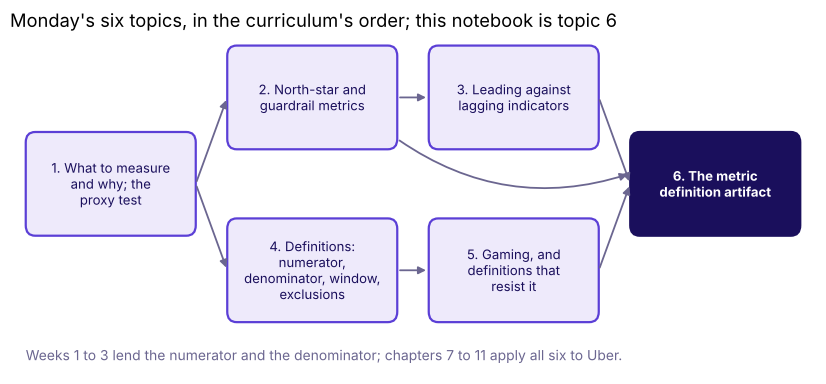

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, VIOLET, ROSE, LAV, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#D9A7FF", "#6B6690"

from matplotlib.patches import FancyBboxPatch, Patch

TOPICS = ["1. What to measure\nand why; the\nproxy test", "2. North-star and\nguardrail metrics",
          "3. Leading against\nlagging indicators", "4. Definitions:\nnumerator,\ndenominator, window,\nexclusions",
          "5. Gaming, and\ndefinitions that\nresist it", "6. The metric\ndefinition artifact"]
PLACE = [(1.6, 2.25), (4.8, 3.5), (8.0, 3.5), (4.8, 1.0), (8.0, 1.0), (11.2, 2.25)]
LINKS = [(0, 1), (1, 2), (0, 3), (3, 4), (2, 5), (4, 5)]


def topic_map(lit):
    """Monday's six topics in the curriculum's order, joined as the deck's concept map joins them."""
    fig, ax = plt.subplots(figsize=(10.4, 4.4))
    w, h = 2.7, 1.5
    for a, b in LINKS:
        (xa, ya), (xb, yb) = PLACE[a], PLACE[b]
        ax.annotate("", xy=(xb - w / 2, yb), xytext=(xa + w / 2, ya),
                    arrowprops={"arrowstyle": "-|>", "color": MUTED, "lw": 1.3})
    (x2, y2), (x6, y6) = PLACE[1], PLACE[5]   # chapter 2's guardrails feed the page, curved under box 3
    ax.annotate("", xy=(x6 - w / 2, y6 + 0.15), xytext=(x2 + w / 2, y2 - 0.6),
                arrowprops={"arrowstyle": "-|>", "color": MUTED, "lw": 1.3, "connectionstyle": "arc3,rad=0.25"})
    for i, ((x, y), label) in enumerate(zip(PLACE, TOPICS), start=1):
        on = i == lit
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.15",
                                    fc=INK if on else "#EEEAFB", ec=INK if on else VIOLET, lw=1.6))
        ax.text(x, y, label, ha="center", va="center", fontsize=9.5, color="white" if on else INK,
                fontweight="bold" if on else "normal")
    ax.text(0.25, -0.3, "Weeks 1 to 3 lend the numerator and the denominator; chapters 7 to 11 apply all six to Uber.",
            fontsize=10, color=MUTED)
    ax.set_xlim(0, 12.8)
    ax.set_ylim(-0.5, 4.4)
    ax.axis("off")
    ax.set_title(f"Monday's six topics, in the curriculum's order; this notebook is topic {lit}", loc="left")
    plt.show()

topic_map(6)

## What does the shop's table hold?

The **metric definition artifact** is one page a company adopts, so teams argue about one written
thing instead of three remembered ones. This notebook writes the page for Balaji Kirana (invented)
on the same 50 orders as notebook 05, loaded again so this notebook stands alone. This cell loads
the orders and prints every row.

In [2]:
orders = pd.read_csv("../data/C2_W04_D01_kirana_deliveries_STUDENT.csv")
print("Balaji Kirana's four weeks of home deliveries, every order invented for this chapter:")
print(orders.to_string(index=False))
check("50 orders, billed 12, 13, 12 and 13 a week", orders.groupby("week").size().tolist() == [12, 13, 12, 13])

Balaji Kirana's four weeks of home deliveries, every order invented for this chapter:
order_id  week  day  marked_done  otp_confirmed  minutes_from_typed_dispatch  minutes_from_bill  complaint
     K01     1    1         True           True                           12                 15      False
     K02     1    1         True           True                           19                 22      False
     K03     1    1         True          False                           11                 34      False
     K04     1    2         True           True                           20                 42      False
     K05     1    2         True           True                           12                 41      False
     K06     1    3         True          False                            9                 21      False
     K07     1    5         True           True                            9                 25      False
     K08     1    5         True           True           

## How many of the seven lines does the weak page hold?

The page has seven lines, in this order: the **numerator** (what is counted, with its receipt);
the **denominator** (divided by what, with its count printed); the **window** (over which
period); the **exclusions** (what leaves both counts, each change dated); what it **does not
reward** (behaviour the number refuses to pay for); the **guardrails** (two or three numbers that
must not fall); and the **gaming note** (the way of gaming each guardrail catches).

**Predict before you run.** The son's growth plan reads "Deliveries, monthly, plus 20 percent".
How many of the seven lines does it hold?

a) One: only what is counted.
b) Two: what is counted, and over when.
c) Four: the lines that make it computable.
d) All seven: a name, a window and a target.

The next cell reads the weak page by hand, one line at a time, then by code, and checks that the
two agree.

In [3]:
LINES = ["numerator", "denominator", "window", "exclusions", "does_not_reward", "guardrails", "gaming_note"]
weak = {"numerator": "deliveries", "window": "monthly"}     # "Deliveries, monthly, plus 20 percent"

# By hand, one line per step: which of the seven does the weak page write?
hand_held = ["numerator", "window"]    # "deliveries" is line 1, with no receipt; "monthly" is line 3
hand_blank = 7 - len(hand_held)        # five lines left blank; "plus 20 percent" is a target, no line at all

# By code
blank = [line for line in LINES if not weak.get(line)]
print("written on the weak page:", [line for line in LINES if weak.get(line)])
print("blank on the weak page:", blank)
check("hand and code agree: the weak page writes 2 of the 7 lines and leaves 5 blank",
      len(blank) == hand_blank and [line for line in LINES if line not in blank] == hand_held)

written on the weak page: ['numerator', 'window']
blank on the weak page: ['denominator', 'exclusions', 'does_not_reward', 'guardrails', 'gaming_note']
PASS hand and code agree: the weak page writes 2 of the 7 lines and leaves 5 blank


**What happened.** The answer is b: "deliveries" is line 1 with no receipt and "monthly" is line
3; "plus 20 percent" is a target, which says how much and never what. The misconception under d
is that a metric is defined once it has a name and a target.

## What does the full page say, and what does each page read?

This cell writes the full page for the shop as a seven-key dictionary and draws the two pages
side by side, line by line.

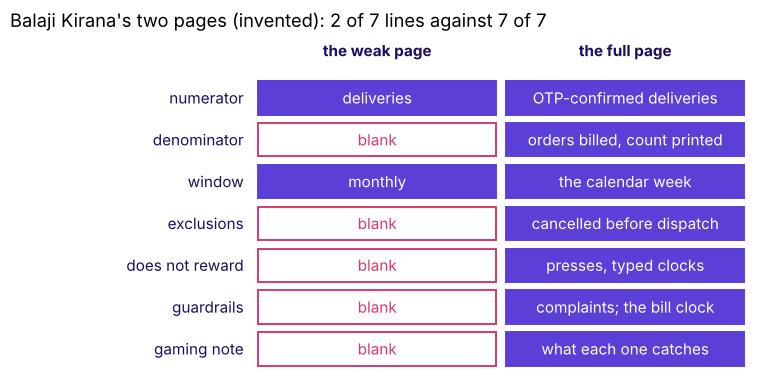

In [4]:
full = {"numerator": "deliveries confirmed with the customer's OTP",
        "denominator": "orders billed that week, the count printed beside the rate",
        "window": "the calendar week",
        "exclusions": "orders the customer cancelled before dispatch, each change dated; none in these four weeks",
        "does_not_reward": "a done press with no OTP, a dispatch time typed by hand, a shrinking order count",
        "guardrails": ["complaints per 100 orders billed", "confirmed deliveries within 30 minutes of the bill"],
        "gaming_note": {"complaints per 100 orders billed": "catches an OTP asked for by phone before the goods arrive",
                        "confirmed deliveries within 30 minutes of the bill": "catches a dispatch time typed late"}}
SHORT = {"numerator": "OTP-confirmed deliveries", "denominator": "orders billed, count printed",
         "window": "the calendar week", "exclusions": "cancelled before dispatch",
         "does_not_reward": "presses, typed clocks", "guardrails": "complaints; the bill clock",
         "gaming_note": "what each one catches"}
fig, ax = plt.subplots(figsize=(9.6, 4.4))
for r, line in enumerate(LINES):
    y = len(LINES) - 1 - r
    ax.text(-0.15, y, line.replace("_", " "), ha="right", va="center", color=INK)
    for c, (page, text) in enumerate(((weak, weak.get(line) or "blank"), (full, SHORT[line]))):
        filled = bool(page.get(line))
        ax.add_patch(plt.Rectangle((c * 2.6, y - 0.4), 2.5, 0.8, fc=VIOLET if filled else "white",
                                   ec=VIOLET if filled else ROSE, lw=1.4))
        ax.text(c * 2.6 + 1.25, y, text, ha="center", va="center", color="white" if filled else ROSE)
ax.text(1.25, 7.0, "the weak page", ha="center", fontweight="bold", color=INK)
ax.text(3.85, 7.0, "the full page", ha="center", fontweight="bold", color=INK)
ax.set_xlim(-2.6, 5.2)
ax.set_ylim(-0.6, 7.5)
ax.axis("off")
ax.set_title("Balaji Kirana's two pages (invented): 2 of 7 lines against 7 of 7", loc="left")
plt.show()

The weak page writes two lines and the full page all seven. The next cell reads both pages on
the four weeks: the weak page counts every done press, and the full page counts OTP-confirmed
deliveries over the orders billed, with its two guardrails beside it.

      billed  marked  confirmed
week                           
1         12      12         10
2         13      13         10
3         12      12         10
4         13      13         10
{'full page, the four weeks': np.float64(0.8), 'complaints per 100 orders billed': 12, 'confirmed deliveries within 30 minutes of the bill': np.float64(0.75)}


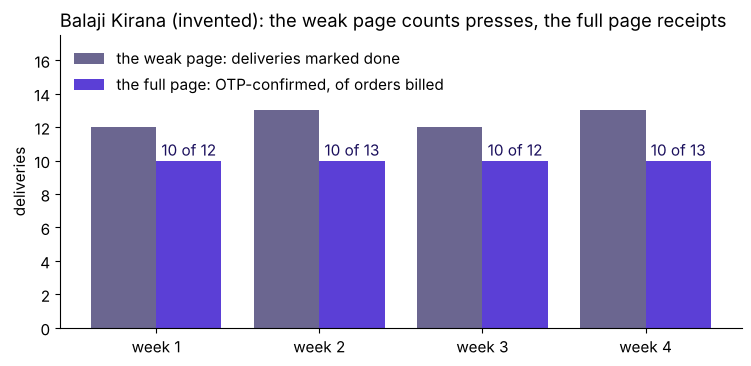

PASS the weak page reads 12 or 13 a week, the full page 10 confirmed every week
PASS the full page reads 0.80 over the four weeks, its guardrails 12 per 100 and 0.75


In [5]:
week = orders.groupby("week").agg(billed=("order_id", "size"), marked=("marked_done", "sum"),
                                  confirmed=("otp_confirmed", "sum"))
print(week)
confirmed = orders[orders["otp_confirmed"]]
reading = {"full page, the four weeks": round(orders["otp_confirmed"].sum() / len(orders), 2),
           "complaints per 100 orders billed": round(100 * orders["complaint"].sum() / len(orders)),
           "confirmed deliveries within 30 minutes of the bill": round((confirmed["minutes_from_bill"] <= 30).mean(), 2)}
print(reading)
fig, ax = plt.subplots(figsize=(8.8, 3.8))
ax.bar(week.index - 0.2, week["marked"], width=0.4, color=MUTED, label="the weak page: deliveries marked done")
ax.bar(week.index + 0.2, week["confirmed"], width=0.4, color=VIOLET, label="the full page: OTP-confirmed, of orders billed")
for w, row in week.iterrows():
    ax.text(w + 0.2, row["confirmed"] + 0.3, f"{row['confirmed']} of {row['billed']}", ha="center", color=INK)
ax.set_xticks(week.index, [f"week {w}" for w in week.index])
ax.set_ylim(0, 17.5)
ax.set_ylabel("deliveries")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Balaji Kirana (invented): the weak page counts presses, the full page receipts", loc="left")
plt.show()
check("the weak page reads 12 or 13 a week, the full page 10 confirmed every week",
      week["marked"].tolist() == [12, 13, 12, 13] and week["confirmed"].tolist() == [10, 10, 10, 10])
check("the full page reads 0.80 over the four weeks, its guardrails 12 per 100 and 0.75",
      list(reading.values()) == [0.8, 12, 0.75])

**What happened.** Week by week the weak page reads 12 or 13 deliveries, every press counted; the
full page reads 10 confirmed in each week out of 12 or 13 orders billed, 40 of 50 over the four
weeks, 0.80. Its guardrails read 12 complaints per 100 orders billed, and 30 of the 40 confirmed
deliveries within 30 minutes of the bill, 0.75.

Named last: the **metric definition artifact** is the seven-line page a company adopts, four
lines that make the number computable and three that make it safe to pay for. The course outline
sets the bar in its own words: a definition is complete only when it names its numerator, its
denominator, its window, and what it deliberately does not reward. The page adds the exclusions
from chapter 4, since an exclusion changed without a date moves the number with nobody told.
Once the numerator needs an OTP, a press at the gate pays nothing, so the complaints guardrail
watches the move that is left: an OTP asked for by phone before the goods arrive.

## Can a check find a blank line, or a guardrail that catches nothing?

This cell writes the check as a short function. It lists every line left blank, and every
guardrail the gaming note does not say it catches, since a guardrail earns its place by the
gaming it catches (chapter 2's third rule). **The trap:** the son adds "orders billed up 20
percent" as a third guardrail. It is a growth target, one more number to chase, and its gaming
note names nothing it catches, so the check flags it. A shrinking order count is already on the
page twice: the denominator prints the count beside the rate, and the line on what the page does
not reward names it. The fix is to drop the target.

In [6]:
def written(value):
    """A line counts as written when it holds something other than the ____ placeholder."""
    return bool(value) and "____" not in str(value)

def missing_lines(page):
    """The page's blank lines, then every guardrail its gaming note does not say it catches."""
    blank_lines = [line for line in LINES if not written(page.get(line))]
    note = page.get("gaming_note") or {}
    unnamed = [g for g in page.get("guardrails") or [] if not written(note.get(g))]
    return blank_lines + [f"a guardrail that catches nothing named: {g}" for g in unnamed]

trap = {**full, "guardrails": full["guardrails"] + ["orders billed up 20 percent"]}
for name, page in (("the weak page", weak), ("the full page", full), ("the full page plus a growth target", trap)):
    print(f"{name}: {missing_lines(page) or 'nothing missing'}")
check("the check finds the weak page's five blank lines", missing_lines(weak) == blank)
check("the full page passes the check", missing_lines(full) == [])
check("a growth target added as a guardrail is flagged",
      missing_lines(trap) == ["a guardrail that catches nothing named: orders billed up 20 percent"])

the weak page: ['denominator', 'exclusions', 'does_not_reward', 'guardrails', 'gaming_note']
the full page: nothing missing
the full page plus a growth target: ['a guardrail that catches nothing named: orders billed up 20 percent']
PASS the check finds the weak page's five blank lines
PASS the full page passes the check
PASS a growth target added as a guardrail is flagged


### Your turn: does your page for the driving school pass the check?

Write chapter 2's driving school (invented) as a seven-line page whose north star is licences per
learner who enrolled. Two lines are filled for you; fill the other five, naming in the gaming
note each guardrail you list and what it catches. Two hints: for the exclusions, think of learners
who left before their first lesson; for a guardrail, ask how an instructor could raise licences
per enrolled learner without teaching better, for example by turning away slow learners at
enrolment. Each key of the gaming note must repeat a guardrail's words exactly, since the check
matches them. In the empty cell below, edit and run:

```python
school_page = {"numerator": "learners who passed the licence test",
               "denominator": "____",
               "window": "the calendar year",
               "exclusions": "____",
               "does_not_reward": "____",
               "guardrails": ["____"],
               "gaming_note": {"____": "____"}}
```

The check under it runs `missing_lines` on your page and passes when nothing is missing.

In [7]:
mine = globals().get("school_page")
if mine is None:
    print("Store school_page in the empty cell above, then run this cell again.")
else:
    gaps = missing_lines(mine)
    print("nothing missing: the page holds all seven lines" if not gaps else f"not yet, still missing: {gaps}")

Store school_page in the empty cell above, then run this cell again.


## What does chapter 6 leave?

1. The page has seven lines: numerator, denominator, window, exclusions, what it does not reward,
   guardrails and the gaming note.
2. The weak page writes two of them; "plus 20 percent" is a target, and no line at all.
3. The full page counts OTP-confirmed deliveries over orders billed, by calendar week, and reads
   0.80 over the four weeks (invented), with its guardrails at 12 complaints per 100 orders billed
   and 0.75 within 30 minutes of the bill.
4. `missing_lines(page)` finds a blank line, and a guardrail the gaming note does not say it
   catches.

**The rules.**

- Write all seven lines before anyone is paid on the number.
- The first four lines make it computable; the last three make it safe to pay for.
- A target is no line of a definition: "plus 20 percent" says how much and never what.
- When teams disagree, change a line on the page and date it.

**In the interview.** [D] Three departments each want their own target; how do you get to one,
and what do you say to the two who lose?

**Where it goes next.** After the break, `C2_W04_D01_07_proxy_test_on_twelve_rows_STUDENT.ipynb`
opens the Uber case on six drivers counted by hand, and
`C2_W04_D01_09_north_star_guardrails_cost_STUDENT.ipynb` fills the same seven lines for Uber's
scheme with the room; the Kalpa lab fills them for Kalpa's growth plan.